# Estabilidad del capital medida sobre historias independientes de verdad conocida

**Pregunta:** ¿Cuán inestable es el capital de riesgo operacional de 99,9% estimado sobre historias independientes de verdad conocida, cuán rápido lo corrige más historia, y con qué frecuencia un banco cercano a un índice de cola de 1 concluye algo equivocado sobre su pérdida media?


- **Nivel:** 4, métodos propuestos
- **Requisitos previos:** los notebooks 02, 06 y 07 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- describir el diseño del experimento de estabilidad del caso C17: cuatro índices de cola, dos largos de historia, dos umbrales de recolección, 1.000 historias independientes por celda, un cuantil verdadero conocido;
- leer, desde los documentos versionados, la dispersión, el sesgo, la proporción de historias que subestiman y el número de historias en que cada estimador está definido;
- reproducir el efecto del largo de la historia sobre la dispersión con historias nuevas y la prueba `oprisk.capital_stability` del motor;
- medir con qué frecuencia un banco concluiría, desde sus propios datos, que la media de sus pérdidas es infinita o finita cuando no lo es;
- decir con precisión qué afirma la declaración, cuál es su evidencia y qué no afirma.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. El generador del caso C17 y sus estimadores viven en `data-pipeline/pipeline/cases/c17/`, que no es un paquete instalado: este notebook carga esos módulos por su ruta (importar todo el paquete `data-pipeline` importaría todos los casos y sus dependencias pesadas). La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate, distributions, sma
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Las cuatro variantes del caso C17 (índices de cola 0,6, 0,8, 0,96 y 1,1) del banco sintético.

- **Archivos que se leen:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` y `xi-1-1.json`: `outputs.cells` (por celda, las semillas de las replicaciones y el resumen de cada estimador sobre 1.000 historias, y el perfil del índice de cola ajustado), `outputs.truth` (los parámetros verdaderos y el cuantil verdadero con su verificación Monte Carlo) y `tests` (las filas versionadas de `oprisk.capital_stability`).
- **Qué está versionado y qué no:** los documentos guardan los resúmenes de 16.000 historias, no las historias. Las historias nuevas se generan con el generador del caso, cargado por su ruta como en el notebook 02, con semillas fuera de los rangos versionados.
- **Qué es sintético:** el banco, sus pérdidas y los escenarios. La severidad es exactamente Pareto generalizada sobre EUR 10.000, con la escala ajustada a medianas publicadas del ejercicio de datos de pérdida de 2008 del Comité de Basilea (BCBS, 2009, `derived-only`).

La celda siguiente carga los documentos y el generador.

In [2]:
# Cargar los cuatro documentos de las variantes y el generador y el estimador del caso por ruta
ROOT = Path("../../..").resolve()
docs = {
    name: json.loads(
        (ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")
    ) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")
}
sys.dont_write_bytecode = True
paquete_caso = types.ModuleType("c17")
paquete_caso.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = paquete_caso
from c17 import generator, params as case_params, replicate

print(
    "variantes:", list(docs), "| calculado por riskvalidation",
    {d["provenance"]["riskvalidation_version"] for d in docs.values()}, "| instalado", md.version("riskvalidation")
)

variantes: ['xi-0-6', 'xi-0-8', 'xi-0-96', 'xi-1-1'] | calculado por riskvalidation {'1.1.0'} | instalado 1.1.0


## Método

### Paso 1: el diseño

El experimento cruza cuatro índices de cola, dos largos de historia (5 y 10 años) y dos umbrales de recolección (EUR 10.000 y 20.000): 16 celdas. En cada celda el caso simula 1.000 historias desde rangos de semillas disjuntos, de modo que las historias son independientes, registra solo las pérdidas sobre el umbral de la celda y corre cada estimador de la escalera sobre cada una. El cuantil de 99,9% verdadero de la pérdida anual de cada variante se conoce por construcción: el método de Fourier en una grilla fina, verificado con un Monte Carlo de 10.000.000 de años. La celda siguiente verifica desde los documentos que los 16 rangos de semillas no se solapan, e imprime la verificación Monte Carlo de cada verdad.

In [3]:
# Verificar que los 16 rangos de semillas son disjuntos y leer la verificación de Monte Carlo de cada cuantil verdadero
ranges = []
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        rep = cell["replications"]
        ranges.append((rep["seed_first"], rep["seed_first"] + rep["n_replications"], name, cell["id"]))
ranges.sort()
overlaps = [(a[2:], b[2:]) for a, b in zip(ranges, ranges[1:]) if a[1] > b[0]]
print(
    "celdas:", len(ranges), "| historias:", sum(r[1] - r[0] for r in ranges), "| rangos de semillas solapados:",
    len(overlaps), "| replicaciones fallidas:",
    sum(c["replications"]["n_failed"] for d in docs.values() for c in d["outputs"]["cells"])
)
for name, doc in docs.items():
    q = doc["outputs"]["truth"]["annual_loss_quantile"]
    print(
        "%-8s cuantil verdadero %15s | verificación Monte Carlo %15s +/- %12s (%.2f%%) | coincide a 3 se %s" % (
            name, format(q["value_eur"], ",.0f"), format(q["mc_check"]["value_eur"], ",.0f"),
            format(q["mc_check"]["standard_error_eur"], ",.0f"),
            100 * q["mc_check"]["standard_error_eur"] / q["value_eur"], "sí" if q["mc_check"]["agrees"] else "no"
        )
    )

celdas: 16 | historias: 16000 | rangos de semillas solapados: 0 | replicaciones fallidas: 0
xi-0-6   cuantil verdadero      33,897,000 | verificación Monte Carlo      33,806,597 +/-      173,397 (0.51%) | coincide a 3 se sí
xi-0-8   cuantil verdadero     163,483,000 | verificación Monte Carlo     162,770,645 +/-    1,238,015 (0.76%) | coincide a 3 se sí
xi-0-96  cuantil verdadero     634,865,452 | verificación Monte Carlo     629,494,317 +/-    5,917,877 (0.93%) | coincide a 3 se sí
xi-1-1   cuantil verdadero   2,148,602,460 | verificación Monte Carlo   2,119,449,230 +/-   21,331,165 (0.99%) | coincide a 3 se sí


Antes de juzgar a los estimadores frente a la verdad, la verdad misma merece una comprobación en vivo. La siguiente celda recalcula el cuantil de 99,9% verdadero de la variante con índice de cola 0,8 con el método de Fourier del motor sobre la grilla del caso, y lo pone junto al valor versionado.

In [4]:
# Recalcular el cuantil de 99,9% verdadero de la variante con índice de cola 0,8 por el método de Fourier
truth08 = docs["xi-0-8"]["outputs"]["truth"]
sev08 = (truth08["severity"]["tail_index"], truth08["severity"]["scale_eur"], truth08["severity"]["location_eur"])
grid_step = truth08["annual_loss_quantile"]["grid_step_eur"]
masses = aggregate.discretise_severity("gpd", sev08, grid_step, 2 ** 19)
pmf = aggregate.fft_aggregate("poisson", (truth08["frequency"]["lambda_per_year"],), masses, padding_factor=2)
q_fourier = aggregate.quantile_from_pmf(pmf, grid_step, 0.999)
print("masa más allá de la grilla: %.2e | cuantil recalculado EUR %s | versionado EUR %s" %
      (1.0 - pmf.sum(), format(q_fourier, ",.0f"), format(truth08["annual_loss_quantile"]["value_eur"], ",.0f")))

masa más allá de la grilla: 2.26e-04 | cuantil recalculado EUR 163,483,000 | versionado EUR 163,483,000


### Paso 2: qué se mide en cada historia

Para un estimador con capital $\hat C_k$ en la historia $k$, los resúmenes versionados sobre las 1.000 historias son, relativos al cuantil verdadero $C^\star$:

$$\text{sesgo} = \operatorname{mediana}_k(\hat C_k / C^\star) - 1, \qquad \text{dispersión} = \big(Q_{75} - Q_{25}\big)\big(\hat C_k / C^\star\big), \qquad \text{subestimación} = \frac{1}{1000}\sum_k \mathbf 1\{\hat C_k < C^\star\}$$

junto con el número de historias en que el estimador devuelve un número: un ajuste que no converge, una grilla que no alcanza el cuantil o una media que no existe no da capital, nunca un número de relleno. `oprisk.capital_stability`, del motor, calcula los dos primeros desde un arreglo de capitales. La celda siguiente lee el estimador de empalme para las cuatro variantes y las cuatro celdas e imprime las cuatro cantidades.

In [5]:
# El estimador de empalme en las 16 celdas: sesgo, dispersión, proporción de historias que subestiman, historias con
# capital
print("%-8s %-11s %9s %11s %14s %9s" % ("", "", "sesgo", "dispersión", "subestima", "definido"))
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        splice = cell["capital"]["lda_splice"]
        print(
            "%-8s %-11s %+9.3f %11.3f %14.3f %9d" % (
                name, cell["id"], splice["ratio_to_truth"]["median"] - 1.0, splice["iqr_over_truth"],
                splice["share_underestimating"], splice["n_defined"]
            )
        )

                         sesgo  dispersión      subestima  definido
xi-0-6   y5-h10000      -0.236       1.952          0.558       959
xi-0-6   y5-h20000      -0.236       2.033          0.584       771
xi-0-6   y10-h10000     -0.150       1.429          0.559       996
xi-0-6   y10-h20000     -0.160       1.354          0.568       859
xi-0-8   y5-h10000      -0.337       2.744          0.587       904
xi-0-8   y5-h20000      -0.361       2.560          0.604       682
xi-0-8   y10-h10000     -0.184       1.776          0.552       971
xi-0-8   y10-h20000     -0.091       1.983          0.530       727
xi-0-96  y5-h10000      -0.219       3.104          0.566       725
xi-0-96  y5-h20000      -0.373       3.299          0.560       550
xi-0-96  y10-h10000     -0.236       2.111          0.546       818
xi-0-96  y10-h20000     -0.071       2.228          0.530       572
xi-1-1   y5-h10000      -0.502       3.304          0.568       229
xi-1-1   y5-h20000      -0.280       3.184      

### Paso 3: el efecto del largo de la historia, con historias nuevas

Los resúmenes versionados dicen que la dispersión baja cuando la historia pasa de 5 a 10 años. Podemos verificarlo con historias que el caso nunca usó, y con la prueba propia del motor. La celda siguiente sortea 40 historias independientes nuevas (semillas desde 9.000.000) de la variante con índice de cola 0,8 para cada uno de los dos largos con un umbral de EUR 10.000, corre el estimador del caso (unos 35 segundos en total) y aplica `oprisk.capital_stability` a los capitales del empalme y a la aproximación de pérdida única, frente al cuantil verdadero. Registra además el primer valor de cada perfil del índice de cola ajustado, el del umbral de recolección. Con solo 40 historias los cuartiles son ruidosos; las filas versionadas con 1.000 historias se imprimen a su lado.

In [6]:
# Historias independientes nuevas de la variante con índice de cola 0,8, 5 y 10 años, umbral EUR 10.000
doc08 = docs["xi-0-8"]
variant = generator.variant(0.8)
bi = doc08["outputs"]["bank"]["business_indicator"]["bi_eur"]
true_q = doc08["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
fresh = {}
for years in (5, 10):
    seeds = [9_000_000 + 1000 * years + k for k in range(40)]
    fresh[years] = [replicate.estimate(variant, s, years, 10_000.0, bi, None, 20_000) for s in seeds]
fresh_rows = []
print(
    "%-6s %-6s %5s %11s %9s %8s | %s" % (
        "años", "peldaño", "n", "dispersión", "sesgo", "semáforo", "versionado sobre 1000: dispersión, sesgo"
    )
)
for years in (5, 10):
    cell = next(c for c in doc08["outputs"]["cells"] if c["id"] == "y%d-h10000" % years)
    for rung in ("lda_splice", "sla"):
        capitals = np.array([r[rung] for r in fresh[years]])
        capitals = capitals[np.isfinite(capitals)]
        result = oprisk_tests.capital_stability(capitals, true_q, model_id=rung)
        stored = (cell["capital"][rung]["iqr_over_truth"], cell["capital"][rung]["ratio_to_truth"]["median"] - 1.0)
        fresh_rows.append((years, rung, capitals.size, result.metric, result.statistic, *stored))
        print(
            "%-6d %-6s %5d %11.3f %+9.3f %8s | %.3f %+.3f" % (
                years, rung, capitals.size, result.metric, result.statistic, result.light.value, *stored
            )
        )

años   peldaño     n  dispersión     sesgo semáforo | versionado sobre 1000: dispersión, sesgo
5      lda_splice    37       6.116    +0.460      red | 2.744 -0.337
5      sla       40       1.915    +0.146      red | 1.284 -0.082
10     lda_splice    39       1.142    -0.305      red | 1.776 -0.184
10     sla       40       0.773    +0.063      red | 0.823 -0.075


La siguiente celda dibuja las mismas cuatro comparaciones como barras: para el empalme y el enfoque estándar a 5 y a 10 años, la dispersión y el sesgo en nuestras 40 historias nuevas junto a los valores versionados sobre 1.000.

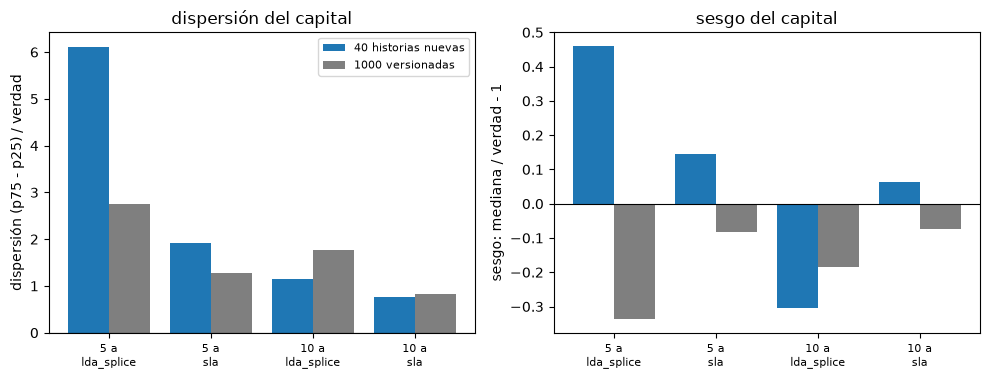

In [7]:
# Dibujar la dispersión y el sesgo de las historias nuevas frente a los valores versionados
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))
labels = ["%d a\n%s" % (r[0], r[1]) for r in fresh_rows]
pos = np.arange(len(labels))
panels = [(left, 3, 5, "dispersión (p75 - p25) / verdad"), (right, 4, 6, "sesgo: mediana / verdad - 1")]
for axis, fresh_col, stored_col, ylabel in panels:
    axis.bar(pos - 0.2, [r[fresh_col] for r in fresh_rows], 0.4, color="tab:blue", label="40 historias nuevas")
    axis.bar(pos + 0.2, [r[stored_col] for r in fresh_rows], 0.4, color="tab:gray", label="1000 versionadas")
    axis.axhline(0.0, color="black", linewidth=0.8)
    axis.set_xticks(pos)
    axis.set_xticklabels(labels, fontsize=8)
    axis.set_ylabel(ylabel)
left.set_title("dispersión del capital")
right.set_title("sesgo del capital")
left.legend(fontsize=8)
fig.tight_layout()
plt.show()

A la izquierda, cuarenta historias nuevas reproducen la dirección del resultado versionado: la dispersión del empalme baja al duplicarse la historia, de 6,116 a 1,142 aquí y de 2,744 a 1,776 sobre 1.000 historias. Las barras nuevas quedan lejos de las versionadas a 5 años porque cuarenta historias no fijan un cuantil de una razón de cola pesada, y el empalme está definido en solo 37 y 39 de ellas. A la derecha el sesgo cambia de signo entre muestras. La corrida nueva confirma el efecto del largo de la historia, no su tamaño; las barras versionadas llevan el tamaño.

### Paso 4: ¿con qué frecuencia un banco concluye algo errado sobre la media?

Un índice de cola de 1 o más significa que la pérdida anual media no existe. Los documentos registran, para cada celda, la proporción de historias cuyo índice de cola Pareto generalizado, ajustado en el umbral de recolección, es 1 o más (`share_at_least_one`). Es la probabilidad de que un banco con ese largo de historia concluya, solo con sus datos, que su pérdida media es infinita. La celda siguiente la imprime para las 16 celdas, junto a la proporción que concluye lo contrario cuando la verdad es 1 o más.

In [8]:
# La proporción de historias cuyo índice de cola ajustado llega a 1, en las 16 celdas (perfil en el umbral de
# recolección)
print("%-8s %-11s %9s %-30s" % ("", "", "xi >= 1", "conclusión errada"))
for name, doc in docs.items():
    true_xi = doc["outputs"]["tail_index"]
    for cell in doc["outputs"]["cells"]:
        share = cell["threshold_stability"][0]["share_at_least_one"]
        wrong = share if true_xi < 1 else 1.0 - share
        verdict = "concluye media infinita" if true_xi < 1 else "concluye media finita"
        print("%-8s %-11s %9.3f %-30s %.3f" % (name, cell["id"], share, verdict, wrong))

                       xi >= 1 conclusión errada             
xi-0-6   y5-h10000       0.000 concluye media infinita        0.000
xi-0-6   y5-h20000       0.000 concluye media infinita        0.000
xi-0-6   y10-h10000      0.000 concluye media infinita        0.000
xi-0-6   y10-h20000      0.000 concluye media infinita        0.000
xi-0-8   y5-h10000       0.024 concluye media infinita        0.024
xi-0-8   y5-h20000       0.063 concluye media infinita        0.063
xi-0-8   y10-h10000      0.005 concluye media infinita        0.005
xi-0-8   y10-h20000      0.012 concluye media infinita        0.012
xi-0-96  y5-h10000       0.332 concluye media infinita        0.332
xi-0-96  y5-h20000       0.344 concluye media infinita        0.344
xi-0-96  y10-h10000      0.268 concluye media infinita        0.268
xi-0-96  y10-h20000      0.317 concluye media infinita        0.317
xi-1-1   y5-h10000       0.818 concluye media finita          0.182
xi-1-1   y5-h20000       0.732 concluye media finita  

La afirmación sobre la media también se puede correr. La siguiente celda sortea 200 historias nuevas para cada variante y largo (semillas desde 9.200.000, con el umbral de recolección de EUR 10.000), ajusta el índice de cola en el umbral con `tail_index_profile` del motor y cuenta cuántas llegan a 1, junto a la proporción versionada de la misma celda.

In [9]:
# Ajustar el índice de cola en el umbral de recolección en 200 historias nuevas por variante y largo y contar las
# que llegan a 1
share_live = {}
print("%-8s %5s | %12s | %s" % ("", "años", "nuevas, xi>=1", "versionado, xi>=1"))
for k, (name, doc) in enumerate(docs.items()):
    variant_k = generator.variant(doc["outputs"]["tail_index"])
    for years in (5, 10):
        first = 9_200_000 + 10_000 * k + 1000 * years
        xi_hat = []
        for seed in range(first, first + 200):
            amounts = generator.draw_history(variant_k, seed, years).recorded(10_000.0).amounts
            xi_hat.append(distributions.tail_index_profile(amounts, np.array([10_000.0])).xi[0])
        share_live[(name, years)] = float(np.mean(np.array(xi_hat) >= 1.0))
        cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y%d-h10000" % years)
        print(
            "%-8s %5d | %12.3f | %.3f" % (
                name, years, share_live[(name, years)], cell["threshold_stability"][0]["share_at_least_one"]
            )
        )

          años | nuevas, xi>=1 | versionado, xi>=1
xi-0-6       5 |        0.000 | 0.000
xi-0-6      10 |        0.000 | 0.000
xi-0-8       5 |        0.020 | 0.024
xi-0-8      10 |        0.000 | 0.005
xi-0-96      5 |        0.270 | 0.332
xi-0-96     10 |        0.255 | 0.268
xi-1-1       5 |        0.805 | 0.818
xi-1-1      10 |        0.935 | 0.912


Un banco cerca de 1 ve además que su índice de cola deriva con el umbral. La siguiente celda corre `oprisk.threshold_stability` del motor sobre el perfil de 100 historias nuevas de diez años para las dos variantes más cercanas a 1 y cuenta los semáforos.

In [10]:
# La prueba de estabilidad por umbral sobre el perfil de 100 historias nuevas de diez años, índice de cola 0,96 y 1,1
for k, name in enumerate(("xi-0-96", "xi-1-1")):
    variant_k = generator.variant(docs[name]["outputs"]["tail_index"])
    counts = {"green": 0, "amber": 0, "red": 0}
    for seed in range(9_300_000 + 1000 * k, 9_300_000 + 1000 * k + 100):
        amounts = generator.draw_history(variant_k, seed, 10).recorded(10_000.0).amounts
        profile = distributions.tail_index_profile(amounts, 10_000.0 * np.array([1.0, 2.0, 4.0, 8.0]))
        xi_profile = np.where(profile.converged, profile.xi, np.nan)
        light = oprisk_tests.threshold_stability(profile.thresholds, xi_profile, model_id="lda-splice").light.value
        counts[light] += 1
    print(name, "| semáforos de 100 historias:", counts)

xi-0-96 | semáforos de 100 historias: {'green': 21, 'amber': 66, 'red': 13}
xi-1-1 | semáforos de 100 historias: {'green': 17, 'amber': 59, 'red': 24}


### Paso 5: de dónde no viene la inestabilidad

La dispersión podría venir en principio de la simulación usada para construir la verdad o de los estimadores, y no de los datos. La verificación Monte Carlo de la verdad tiene un error estándar bajo 1% del cuantil (paso 1), los peldaños de empalme y de Panjer no tienen Monte Carlo alguno, y el caso registra que las agregaciones de Panjer y de Fourier de la misma ley ajustada coinciden en las historias donde existen ambas (`aggregation_agreement`). Así que la dispersión de decenas o cientos de por ciento viene de estimar la cola con 5 o 10 años de pérdidas. La celda siguiente imprime la mayor diferencia relativa entre Panjer y Fourier en las celdas, y el número de historias comparadas.

In [11]:
# La concordancia entre las agregaciones de Panjer y de Fourier de la misma ley ajustada, en las 16 celdas
agreements = [c["aggregation_agreement"] for d in docs.values() for c in d["outputs"]["cells"]]
print(
    "mayor diferencia relativa Panjer - Fourier:", max(a["max_rel_diff_panjer_fft"] for a in agreements),
    "| historias comparadas:", sum(a["n_compared"] for a in agreements)
)

mayor diferencia relativa Panjer - Fourier: 0.000968054211 | historias comparadas: 11552


El enfoque estándar es la comparación que necesita la afirmación. La siguiente celda calcula su capital con `sma_capital` del motor en 200 historias nuevas de diez años de cada variante y pone la mediana y la dispersión sobre el cuantil verdadero junto a los valores versionados.

In [12]:
# El capital de la SMA sobre el cuantil verdadero en 200 historias nuevas de diez años por variante
for k, (name, doc) in enumerate(docs.items()):
    variant_k = generator.variant(doc["outputs"]["tail_index"])
    bi_k = doc["outputs"]["bank"]["business_indicator"]["bi_eur"]
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    first = 9_400_000 + 1000 * k
    histories = [generator.draw_history(variant_k, s, 10).recorded(10_000.0) for s in range(first, first + 200)]
    ratios = np.array([sma.sma_capital(bi_k, h.annual).orc for h in histories]) / truth_q
    q25, q50, q75 = np.percentile(ratios, [25, 50, 75])
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h10000")["sma"]["orc_over_true_quantile"]
    print(
        "%-8s SMA / verdad: mediana %.3f, RIC %.3f | versionado: mediana %.3f, RIC %.3f" % (
            name, q50, q75 - q25, cell["median"], cell["p75"] - cell["p25"]
        )
    )

xi-0-6   SMA / verdad: mediana 4.017, RIC 0.140 | versionado: mediana 4.030, RIC 0.144
xi-0-8   SMA / verdad: mediana 0.881, RIC 0.061 | versionado: mediana 0.882, RIC 0.058
xi-0-96  SMA / verdad: mediana 0.240, RIC 0.025 | versionado: mediana 0.242, RIC 0.030
xi-1-1   SMA / verdad: mediana 0.077, RIC 0.014 | versionado: mediana 0.078, RIC 0.016


## Comparación

Lo que se sabe antes de este notebook, desde los notebooks y fuentes de este tema. El capital de riesgo operacional por el enfoque de distribución de pérdidas (LDA) es un cuantil alto de una suma compuesta cuya cola se estima con pocos años de pérdidas recolectadas sobre un umbral (notebooks 01 y 02; Chavez-Demoulin, Embrechts y Neslehova, 2006; Shevchenko, 2010). Se sabe que el error del cuantil Monte Carlo decae como la raíz cuadrada del número de años simulados (Shevchenko, 2010). El Comité de Basilea eliminó el enfoque avanzado por su complejidad y la falta de comparabilidad de los modelos internos (BCBS, 2016), y la crítica académica a su reemplazo argumentó que el enfoque estándar es a su vez inestable e insensible al riesgo (Peters, Shevchenko, Hassani y Chapelle, 2016). La investigación detrás de este caso ilustra la inestabilidad de un LDA cerca de un índice de cola de 1 con una calibración de las medianas de datos de pérdida de 2008 del Comité de Basilea (BCBS, 2009), con salvedades. Lo que esas fuentes no entregan, hasta donde halló la investigación, es la dispersión del capital LDA frente a una verdad conocida, medida sobre muchas historias independientes y varios índices de cola, largos de historia y umbrales.

## Evidencia

**La inestabilidad del capital de riesgo operacional, medida sobre historias independientes de verdad conocida.**

- **Qué agrega.** Para cuatro índices de cola (0,6, 0,8, 0,96 y 1,1), dos largos de historia (5 y 10 años) y dos umbrales de recolección (EUR 10.000 y 20.000), el caso simula 1.000 historias independientes por celda en rangos de semillas disjuntos (16.000 historias). Para cada peldaño de una escalera de estimación de seis peldaños y para el enfoque estándar registra el capital de 99,9% frente al cuantil anual de pérdida verdadero del generador, como la mediana sobre la verdad, el rango intercuartil sobre la verdad, la proporción de historias que subestiman y el número de historias en que el peldaño está definido; y la proporción de historias cuyo índice de cola ajustado llega a 1, es decir, que concluirían una media infinita. En la grilla versionada el rango intercuartil del peldaño de empalme es de 1,35 a 3,30 veces la verdad, las 92 filas de `oprisk.capital_stability` son rojas frente a umbrales internos declarados, entre 27% y 34% de las historias de la variante con índice de cola 0,96 concluyen una media infinita que no existe, y entre 9% y 27% de las de la variante con índice de cola 1,1 concluyen una finita (26,8 a 34,4 % y 8,8 a 26,8 % en el artículo de la inestabilidad). Estas cuatro afirmaciones se escribieron en el diseño después de sortear esas mismas 16.000 historias, así que reproducen la corrida y el artículo las reproduce, no son pruebas que pudieran haber fallado; las 92 filas rojas son las de la escalera de seis peldaños, y las 144 filas de los nueve peldaños que cuenta el artículo, con los cuatro robustos, también son rojas.
- **Evidencia.** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` y `xi-1-1.json` (`outputs.cells`, `outputs.truth`, `tests`), los requisitos CT-1701 a CT-1715 de `docs/design/features/c17/requirements.md`, y este notebook, que verifica el diseño, reproduce el efecto del largo con historias nuevas y con la prueba del motor, e imprime los números.
- **La práctica a la que supera.** La investigación presenta la inestabilidad cerca de un índice de cola de 1 como un caso didáctico a partir de una calibración ilustrativa, con salvedades; el Comité de Basilea da la complejidad y la falta de comparabilidad, no una medición de error, como su razón para eliminar el enfoque avanzado; la crítica académica argumenta la inestabilidad del enfoque estándar. Ninguna de las fuentes halladas mide la dispersión del capital LDA frente a una verdad conocida sobre historias independientes. Esa ausencia es UNVERIFIED más allá de la búsqueda de la propia investigación.
- **Lo que la declaración no dice.** No dice que el LDA sea inutilizable ni que el enfoque estándar tenga razón: el enfoque estándar no está calibrado a un cuantil de 99,9% y aquí solo se compara con el del generador. Trata de un banco sintético cuya severidad se sortea de la familia que suponen los estimadores de cola (lo que favorece a los estimadores) y cuyas luces usan los umbrales propios de Contraste; no dice nada sobre el capital de ningún banco real.

In [13]:
# La evidencia de la afirmación en una tabla: el empalme y el enfoque estándar en las celdas de 10 años, y las
# conclusiones erróneas sobre la media
print(
    "%-8s %-11s %12s %12s %10s %10s %12s" % (
        "", "", "RIC empalme", "definido", "SMA / verdad", "xi >= 1", "xi verdadero"
    )
)
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        if not cell["id"].startswith("y10"):
            continue
        print(
            "%-8s %-11s %12.3f %12d %10.3f %10.3f %12s" % (
                name, cell["id"], cell["capital"]["lda_splice"]["iqr_over_truth"],
                cell["capital"]["lda_splice"]["n_defined"], cell["sma"]["orc_over_true_quantile"]["median"],
                cell["threshold_stability"][0]["share_at_least_one"], doc["outputs"]["tail_index"]
            )
        )
rows = [t for d in docs.values() for t in d["tests"] if t["test_id"] == "oprisk.capital_stability"]
print(
    "filas versionadas de estabilidad del capital:", len(rows), "| rojas:", sum(t["light"] == "red" for t in rows),
    "| filas con valor p:", sum(t["p_value"] is not None for t in rows)
)

                      RIC empalme     definido SMA / verdad    xi >= 1 xi verdadero
xi-0-6   y10-h10000         1.429          996      4.030      0.000          0.6
xi-0-6   y10-h20000         1.354          859      3.975      0.000          0.6
xi-0-8   y10-h10000         1.776          971      0.882      0.005          0.8
xi-0-8   y10-h20000         1.983          727      0.869      0.012          0.8
xi-0-96  y10-h10000         2.111          818      0.242      0.268         0.96
xi-0-96  y10-h20000         2.228          572      0.239      0.317         0.96
xi-1-1   y10-h10000         1.683          128      0.078      0.912          1.1
xi-1-1   y10-h20000         2.319          409      0.077      0.836          1.1
filas versionadas de estabilidad del capital: 156 | rojas: 156 | filas con valor p: 0


La siguiente celda dibuja la evidencia versionada de la afirmación, en dos figuras. La primera es la dispersión del capital del empalme sobre la verdad para cada índice de cola, con 5 y con 10 años de datos, de las celdas con umbral EUR 10.000.

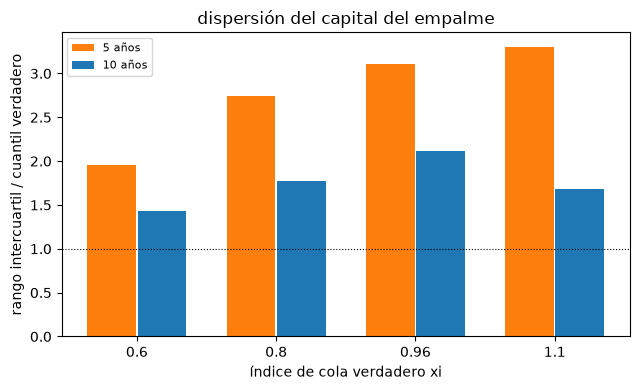

In [14]:
# Dibujar la dispersión del capital del empalme para cada índice de cola y largo de historia
fig, ax = plt.subplots(figsize=(6.5, 4.0))
labels = [str(d["outputs"]["tail_index"]) for d in docs.values()]
positions = np.arange(len(labels))
for offset, years, color in ((-0.18, 5, "tab:orange"), (0.18, 10, "tab:blue")):
    cells_y = [next(c for c in d["outputs"]["cells"] if c["id"] == "y%d-h10000" % years) for d in docs.values()]
    iqr = [cell["capital"]["lda_splice"]["iqr_over_truth"] for cell in cells_y]
    ax.bar(positions + offset, iqr, width=0.35, color=color, label="%d años" % years)
ax.axhline(1.0, color="black", linewidth=0.8, linestyle=":")
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_xlabel("índice de cola verdadero xi")
ax.set_ylabel("rango intercuartil / cuantil verdadero")
ax.set_title("dispersión del capital del empalme")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Todas las barras están en la línea punteada de 1 o sobre ella: el rango del capital del empalme sobre 1.000 historias es tan grande como el propio capital verdadero, con 5 años y todavía con 10, y es mayor, 3,30, para la cola más pesada con 5 años. Duplicar la historia baja las barras de 1,95 a 1,43, de 2,74 a 1,78, de 3,10 a 2,11 y de 3,30 a 1,68, una mejora que nunca lleva a una variante bajo el tamaño de la propia verdad. La figura cubre un umbral; la tabla de arriba tiene las cuatro celdas.

La segunda figura es la proporción de historias cuyo índice de cola ajustado llega a 1, de modo que el banco concluye que su pérdida media es infinita, para cada índice de cola y largo de historia.

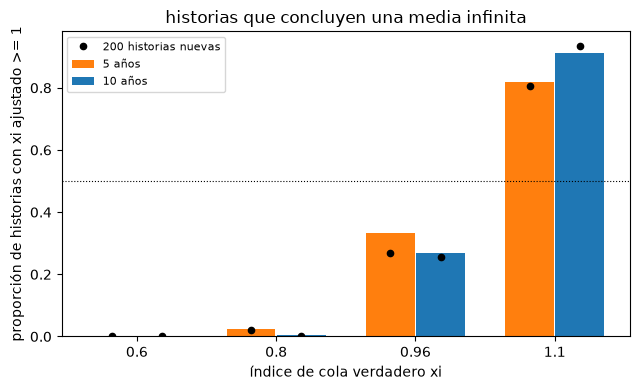

In [15]:
# Dibujar la proporción de historias cuyo índice de cola ajustado llega a 1, por índice de cola y largo de historia
fig, ax = plt.subplots(figsize=(6.5, 4.0))
for offset, years, color in ((-0.18, 5, "tab:orange"), (0.18, 10, "tab:blue")):
    cells_y = [next(c for c in d["outputs"]["cells"] if c["id"] == "y%d-h10000" % years) for d in docs.values()]
    share = [cell["threshold_stability"][0]["share_at_least_one"] for cell in cells_y]
    ax.bar(positions + offset, share, width=0.35, color=color, label="%d años" % years)
    ax.plot(positions + offset, [share_live[(n, years)] for n in docs], "k.", markersize=9)
ax.plot([], [], "k.", markersize=9, label="200 historias nuevas")
ax.axhline(0.5, color="black", linewidth=0.8, linestyle=":")
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_xlabel("índice de cola verdadero xi")
ax.set_ylabel("proporción de historias con xi ajustado >= 1")
ax.set_title("historias que concluyen una media infinita")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Con índices de cola 0,6 y 0,8 casi ninguna historia concluye una media infinita, lo que es correcto porque la media existe. Con 0,96 más de una cuarta parte de las historias llama infinita a una media finita, y con 1,1 las barras son altas pero no llenas: las historias restantes concluyen una media finita donde no existe, de 8,8% a 26,8% sobre las cuatro celdas de la tabla del paso 4. El banco no puede leer la respuesta de sus propios datos cerca de 1. Los puntos negros son 200 historias nuevas por celda, 0,270 y 0,255 con 0,96 y 0,805 y 0,935 con 1,1, cerca de las barras versionadas, de modo que las proporciones son una propiedad de la estimación de la cola y no de un lote de semillas. La figura usa solo el ajuste en el umbral de recolección, así que subestima cuánto se mueve la conclusión con el umbral.

### Dónde cambia o falla el método: cuán larga debe ser una historia para distinguir la media de ninguna

La conclusión errada sobre la media del paso 4 tiene un mecanismo simple. El índice de cola ajustado por máxima verosimilitud es casi normal en torno al $\xi$ verdadero con error estándar $(1+\xi)/\sqrt{n_u}$ en el número de excedencias $n_u$ (la fórmula que el barrido del cuaderno 02 verificó contra el motor), así que la probabilidad de un índice ajustado de 1 o más es

$$\Pr(\hat\xi \ge 1) \approx 1 - \Phi\!\left( \sqrt{n_u}\;\frac{1-\xi}{1+\xi} \right)$$

con $\Phi$ la función de distribución normal estándar. La distancia $1-\xi$ a la línea de media finita y el número de excedencias son los únicos insumos. Un banco puede alargar su historia pero no puede mover su cola, de modo que el régimen donde el método falla es un índice de cola a pocas centésimas de 1, por muchas historias que se promedien. El veredicto errado tiene probabilidad de 5% cuando $\sqrt{n_u}$ llega a $z_{0,95}\,(1+\xi)/|1-\xi|$.

La celda siguiente sortea 200 historias nuevas para cada uno de seis largos, de 3 a 80 años, para las dos variantes cercanas a 1 (índices de cola 0,96 y 1,10), ajusta el índice de cola en el umbral de recolección de EUR 10.000 e imprime la mediana del número de excedencias, la mediana del índice ajustado, la parte de historias en 1 o más y la fórmula normal. Luego imprime el número de excedencias, y los años a la frecuencia del caso, que necesita un veredicto errado de 5%.

In [16]:
# Barrer el largo de la historia para los dos índices de cola cercanos a 1: 200 historias nuevas cada uno
from scipy.stats import norm

YEARS_SWEEP = (3, 5, 10, 20, 40, 80)
length_rows = {}
header = ("xi verdadero", "años", "n mediana", "xi_hat mediano", "parte xi_hat >= 1", "fórmula normal")
print("%8s %6s %9s %14s %18s %15s" % header)
for xi_true in (0.96, 1.1):
    variant_x = generator.variant(xi_true)
    for years in YEARS_SWEEP:
        estimates, sizes = [], []
        for seed in range(9_600_000, 9_600_200):
            amounts_x = generator.draw_history(variant_x, seed, years).recorded(10_000.0).amounts
            estimates.append(distributions.tail_index_profile(amounts_x, np.array([10_000.0])).xi[0])
            sizes.append(amounts_x.size)
        estimates = np.array(estimates)
        n_median = float(np.median(sizes))
        predicted = 1.0 - norm.cdf((1.0 - xi_true) * np.sqrt(n_median) / (1.0 + xi_true))
        length_rows[(xi_true, years)] = (n_median, np.nanmedian(estimates), float(np.mean(estimates >= 1.0)), predicted)
        print("%8.2f %6d %9.1f %14.3f %18.3f %15.3f" % ((xi_true, years) + length_rows[(xi_true, years)]))
z_95 = norm.ppf(0.95)
for xi_true in (0.96, 1.1):
    n_needed = (z_95 * (1.0 + xi_true) / abs(1.0 - xi_true)) ** 2
    per_year = length_rows[(xi_true, 10)][0] / 10.0
    print("xi = %.2f: excedencias para un veredicto errado de 5%% %.0f, unos %.0f años a %.1f al año" % (
        xi_true, n_needed, n_needed / per_year, per_year))

xi verdadero   años n mediana xi_hat mediano  parte xi_hat >= 1  fórmula normal
    0.96      3     217.5          0.954              0.330           0.382
    0.96      5     365.0          0.956              0.325           0.348
    0.96     10     732.0          0.956              0.270           0.290
    0.96     20    1472.0          0.956              0.180           0.217
    0.96     40    2940.5          0.961              0.070           0.134
    0.96     80    5874.0          0.957              0.040           0.059
    1.10      3     253.0          1.093              0.765           0.776
    1.10      5     426.0          1.096              0.790           0.837
    1.10     10     854.0          1.100              0.905           0.918
    1.10     20    1715.0          1.098              0.980           0.976
    1.10     40    3434.0          1.097              0.995           0.997
    1.10     80    6849.5          1.099              1.000           1.000
xi = 0.9

La celda siguiente dibuja la parte de historias con índice de cola ajustado de 1 o más según los años de historia, en eje logarítmico, para ambas variantes, con la simulación como puntos y la fórmula como línea discontinua del mismo color, y una línea horizontal en un medio.

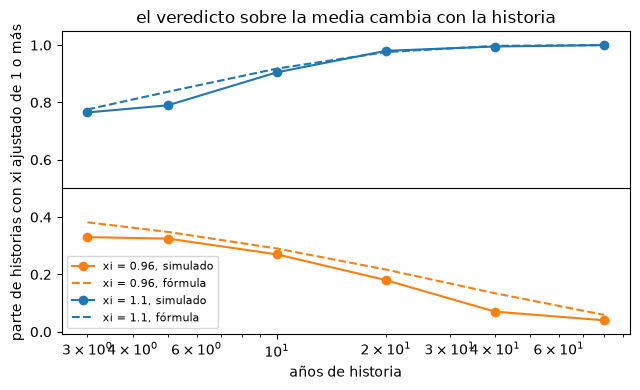

In [17]:
# Dibujar la parte de historias que concluyen una media infinita según el largo de la historia, con la fórmula normal
fig, ax = plt.subplots(figsize=(6.5, 4.0))
for xi_true, color in ((0.96, "tab:orange"), (1.1, "tab:blue")):
    shares = [length_rows[(xi_true, y)][2] for y in YEARS_SWEEP]
    formula_values = [length_rows[(xi_true, y)][3] for y in YEARS_SWEEP]
    ax.semilogx(YEARS_SWEEP, shares, "o-", color=color, label="xi = %s, simulado" % xi_true)
    ax.semilogx(YEARS_SWEEP, formula_values, "--", color=color, label="xi = %s, fórmula" % xi_true)
ax.axhline(0.5, color="black", linewidth=0.8)
ax.set_xlabel("años de historia")
ax.set_ylabel("parte de historias con xi ajustado de 1 o más")
ax.set_title("el veredicto sobre la media cambia con la historia")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las medianas del índice ajustado quedan sobre la verdad en todos los largos (0,954 a 0,961 para un 0,96 verdadero, 1,093 a 1,100 para un 1,10 verdadero), así que el estimador no tiene sesgo; lo que cambia es con qué frecuencia una historia cae del lado errado de 1. Para el 0,96 verdadero la parte en 1 o más es 0,330 con 3 años, 0,270 con 10, 0,180 con 20, 0,070 con 40 y 0,040 con 80, de modo que un banco con diez años concluye una media infinita que no existe en 27% de los casos y uno con 80 años todavía lo hace en 4%. Para el 1,10 verdadero la parte, que ahora es el veredicto correcto, es 0,765, 0,905, 0,980 y 0,995 con 3, 10, 20 y 40 años, así que la media finita concluida por error baja de 9,5% con diez años a 2% con veinte. La fórmula sigue a la simulación dentro de 0,05 para la variante 1,10, y para 0,96 sobreestima la parte hasta en 0,064 con 40 años (0,134 frente a 0,070), un recordatorio de que es una aproximación normal de un estimador asimétrico. Las dos últimas líneas impresas lo convierten en un requisito: distinguir 0,96 de 1 con un error de 5% necesita 6.496 excedencias, unos 89 años a las 73,2 excedencias anuales del caso, mientras que distinguir 1,10 de 1 necesita 1.193, unos 14 años. El barrido mantiene el umbral en EUR 10.000 y una severidad pareto generalizada, la familia que el estimador supone, y no dice nada de una cola real que solo es aproximadamente pareto.

### Úsalo con tus propios datos

Un banco tiene una historia, no mil, así que la medición de este cuaderno no puede repetirse directamente sobre ella: no hay verdad conocida ni historias independientes. Lo que sí puede repetirse es la dispersión del estimador en torno a su propia respuesta, remuestreando los años de la historia, lo que conserva la estructura anual de los conteos. El método espera las pérdidas registradas agrupadas por año como una lista de arreglos en EUR (los años sin pérdidas registradas como arreglos vacíos), el umbral de recolección y el número de remuestreos; no lee ningún documento del contrato, pero su resultado se juzga con la misma prueba del motor que las filas confirmadas, `oprisk.capital_stability`, cuyo cuantil de referencia es aquí el propio capital plug-in de la historia.

La celda siguiente define `bootstrap_stability`, que para cada remuestreo de los años reajusta la cola pareto generalizada y la tasa de Poisson con `fit_severity` y `fit_frequency`, calcula la aproximación de pérdida única con `sla_var` y pasa los 300 capitales a `capital_stability` en torno al capital plug-in. Se llama con una historia nueva de diez años de la variante con índice de cola 0,8 (semilla 9.000.017, fuera de todo rango confirmado), e imprime la dispersión junto a la confirmada sobre 1.000 historias independientes, la parte de remuestreos cuyo índice de cola ajustado llega a 1, y el cuantil verdadero para contrastar.

In [18]:
# Una función que remuestrea los años de una historia, reajusta la cola y la tasa cada vez, y corre la prueba
# de estabilidad sobre los capitales remuestreados en torno al capital plug-in, y su llamada con una historia nueva
from riskvalidation.oprisk import sla


def bootstrap_stability(amounts_by_year, threshold, n_boot, seed, level=0.999):
    rng_boot = np.random.default_rng(seed)
    counts_own = np.array([a.size for a in amounts_by_year])

    def plug_in(indices):
        amounts_b = np.concatenate([amounts_by_year[i] for i in indices])
        tail = distributions.fit_severity("gpd", amounts_b, threshold, truncated=True)
        rate = distributions.fit_frequency(counts_own[indices]).params[0]
        return sla.sla_var(rate, "gpd", tuple(tail.params), level), tail.params[0]

    base_capital, base_xi = plug_in(np.arange(len(amounts_by_year)))
    pairs = [plug_in(rng_boot.integers(0, len(amounts_by_year), len(amounts_by_year))) for _ in range(n_boot)]
    capitals_b = np.array([p[0] for p in pairs])
    verdict = oprisk_tests.capital_stability(capitals_b, base_capital, model_id="bootstrap")
    return base_capital, base_xi, verdict, float(np.mean([p[1] >= 1.0 for p in pairs]))


own_history = generator.draw_history(variant, 9_000_017, 10).recorded(10_000.0)
by_year = np.split(own_history.amounts, np.cumsum(own_history.counts)[:-1])
base_capital, base_xi, boot_verdict, share_infinite = bootstrap_stability(by_year, 10_000.0, 300, 5)
print("años:", len(by_year), "| pérdidas:", own_history.amounts.size, "| índice de cola plug-in: %.4f" % base_xi)
print("capital plug-in (EUR):", format(base_capital, ",.0f"), "| cuantil verdadero (EUR):", format(true_q, ",.0f"))
print("dispersión bootstrap %.3f | sesgo %+.3f | semáforo %s | n %d" % (
    boot_verdict.metric, boot_verdict.statistic, boot_verdict.light.value, boot_verdict.n))
print("parte de remuestreos con índice de cola ajustado de 1 o más:", share_infinite)
print("dispersión confirmada de la aproximación de pérdida única sobre 1.000 historias, 10 años, EUR 10.000:",
      next(c for c in doc08["outputs"]["cells"] if c["id"] == "y10-h10000")["capital"]["sla"]["iqr_over_truth"])

años: 10 | pérdidas: 658 | índice de cola plug-in: 0.8342
capital plug-in (EUR): 211,332,714 | cuantil verdadero (EUR): 163,483,000
dispersión bootstrap 0.631 | sesgo -0.012 | semáforo red | n 300
parte de remuestreos con índice de cola ajustado de 1 o más: 0.0
dispersión confirmada de la aproximación de pérdida única sobre 1.000 historias, 10 años, EUR 10.000: 0.82282264


Lee la salida en cuatro pasos. Primero, la historia: 10 años y 658 pérdidas, un índice de cola plug-in de 0,8342 (el verdadero es 0,80) y un capital plug-in de EUR 211.332.714 frente a un cuantil verdadero de EUR 163.483.000, es decir 1,29 veces la verdad. Segundo, la dispersión bootstrap de 0,631, con semáforo rojo, frente al 0,823 que muestra la celda confirmada sobre 1.000 historias independientes: el remuestreo recupera la mayor parte de la dispersión (77%) desde una sola historia, que es lo que lo hace usable por un banco, y aun así la subestima. Tercero, el sesgo bootstrap de -0,012: se mide contra el capital plug-in, no contra la verdad, así que es casi cero por construcción, y oculta el 29% en que el propio plug-in sobrepasa la verdad. Un banco sin verdad conocida puede medir su dispersión, nunca su sesgo. Cuarto, la parte de remuestreos con índice de cola ajustado de 1 o más es 0,0, de modo que para esta historia la aproximación de pérdida única nunca pierde su media en los 300 remuestreos; para una historia cercana a 1 este es el número a vigilar, porque el barrido anterior muestra qué tan rápido se mueve. El bootstrap remuestrea años completos, así que supone que los años son intercambiables; una tendencia o un cambio de régimen en las pérdidas del banco rompe ese supuesto y la dispersión resulta entonces demasiado pequeña.

## Resultados

**Respuesta:** Sobre 16000 historias independientes el capital del empalme tiene un rango intercuartil de 1,35 a 3,30 veces el cuantil verdadero, las 92 filas versionadas de estabilidad del capital son rojas, y duplicar la historia de 5 a 10 años con índice de cola 0,8 y umbral de EUR 10.000 solo baja el rango versionado de 2,744 a 1,776 (en 40 historias nuevas, de 6,116 a 1,142). Cerca de un índice de cola de 1 un banco no puede leer su media de sus propios datos: con 0,96 la proporción de historias de diez años que llama infinita a la media finita es 0,268 y 0,317 en las dos celdas versionadas y 0,255 en historias nuevas.

- **El diseño se cumple.** Hay 16 celdas y 16.000 historias, ninguno de los 16 rangos de semillas se solapa con otro, ninguna replicación falló, y la verificación Monte Carlo de cada cuantil verdadero tiene un error estándar de entre 0,51% y 0,99% de él y coincide a menos de tres errores estándar.
- **Las historias nuevas coinciden.** El recálculo de Fourier del cuantil verdadero con índice de cola 0,8 da EUR 163.483.000, el valor versionado. En 200 historias nuevas por celda la proporción con índice de cola ajustado de 1 o más es 0,270 y 0,255 con índice 0,96 y 0,805 y 0,935 con 1,1 (5 y 10 años), a menos de 0,07 de los versionados 0,332, 0,268, 0,818 y 0,912; la prueba de estabilidad por umbral del motor pinta de ámbar 66 de 100 historias de diez años con 0,96 y 59 con 1,1, con 13 y 24 en rojo; y la SMA sobre la verdad tiene medianas 4,017, 0,881, 0,240 y 0,077, frente a 4,030, 0,882, 0,242 y 0,078 versionadas.
- **El empalme es inestable en todas las celdas.** Su sesgo, mediana sobre la verdad menos 1, está entre -0,07 y -0,50, su rango intercuartil sobre la verdad entre 1,35 y 3,30, y entre 52% y 60% de las historias subestiman. El peldaño está definido en 128 a 996 de las 1.000 historias, menos con índice de cola 1,1, 10 años y umbral de EUR 10.000.
- **El largo ayuda, despacio.** Con umbral de EUR 10.000 el rango versionado del empalme baja de 1,95 a 1,43, de 2,74 a 1,78, de 3,10 a 2,11 y de 3,30 a 1,68 (índices de cola 0,6, 0,8, 0,96 y 1,1) al duplicarse la historia de 5 a 10 años, aún del orden de la verdad. Con 40 historias nuevas con índice de cola 0,8 la prueba del motor da un rango de 6,12 con 5 años y 1,14 con 10 años para el empalme (37 y 39 historias definidas) y 1,92 y 0,77 para la aproximación, frente a 2,74 y 1,78 y 1,28 y 0,82 versionados. Con 40 historias los cuartiles son ruidosos; el sentido es el mismo.
- **Conclusiones erradas sobre la media.** Ajustado en el umbral de recolección, el índice de cola es 1 o más en 0,0% de las historias de la variante con índice de cola 0,6, en 0,5% a 6,3% con 0,8, en 26,8% a 34,4% con 0,96 (una media finita que el banco llamaría infinita) y en 73,2% a 91,2% con 1,1, de modo que 8,8% a 26,8% de esos bancos concluirían una media finita donde no la hay.
- **No es la simulación.** El error Monte Carlo de la verdad es menor que 1% del cuantil, y las agregaciones de Panjer y de Fourier de la misma ley ajustada difieren en a lo más 0,097% sobre 11.552 historias comparadas. Una dispersión de una a tres veces la verdad viene de estimar la cola con 5 o 10 años de pérdidas.
- **La tabla resumen.** Las 92 filas versionadas de `oprisk.capital_stability` son rojas y ninguna tiene valor p. El enfoque estándar es estable pero lejos de la verdad en las celdas de diez años: 4,03 y 3,98 veces ella con índice de cola 0,6, 0,87 a 0,88 con 0,8, 0,24 con 0,96 y 0,08 con 1,1.
- **Dónde falla.** Con un índice de cola verdadero de 0,96, 27% de las historias de diez años concluyen una media infinita que no existe y 4% de las de 80 años todavía lo hace; distinguir 0,96 de 1 con un error de 5% necesita 6.496 excedencias, unos 89 años a la frecuencia del caso, frente a 1.193 y 14 años para 1,10.
- **Con tus propios datos.** El bootstrap de los años de una historia da una dispersión de 0,631 donde la celda confirmada sobre 1.000 historias independientes da 0,823, y un sesgo de -0,012 medido solo contra el capital plug-in, que a su vez es 1,29 veces el cuantil verdadero.

La declaración queda demostrada con estos números, en este generador y con estos umbrales, y no más.

## Resumen

- El caso C17 mide la estabilidad del capital de riesgo operacional sobre 16.000 historias independientes de un banco sintético con un cuantil verdadero conocido, en cuatro índices de cola, dos largos de historia y dos umbrales.
- El peldaño de empalme tiene un rango intercuartil de 1,35 a 3,30 veces la verdad, que baja solo despacio de 5 a 10 años; la causa es estimar la cola con pocos años de pérdidas, no la simulación.
- Cerca de un índice de cola de 1 un banco sacaría a menudo la conclusión errada sobre si existe su pérdida media: de 27% a 34% con 0,96 y de 9% a 27% con 1,1.
- La declaración está acotada: un generador sintético, una escalera fija, umbrales internos y ningún banco real.

**Qué probar a continuación.** Repite el paso 3 con 100 historias (unos 90 segundos) para estrechar los cuartiles, o para la variante con índice de cola 0,96 para ver la dispersión de la aproximación. Lee `docs/design/features/c17/requirements.md` para los requisitos que sostienen el diseño.

## Referencias

- BCBS (2009), Results from the 2008 Loss Data Collection Exercise for Operational Risk. https://www.bis.org/publ/bcbs160.htm
- BCBS (2016), Standardised Measurement Approach for operational risk, documento consultivo. https://www.bis.org/bcbs/publ/d355.htm
- Chavez-Demoulin, V., Embrechts, P. y Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008
- Peters, G. W., Shevchenko, P. V., Hassani, B. y Chapelle, A. (2016), Should the advanced measurement approach be replaced with the standardized measurement approach for operational risk? https://arxiv.org/abs/1607.02319
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40 (el error del cuantil de un Monte Carlo decae como la raíz cuadrada del número de años). https://arxiv.org/abs/1008.1108 y https://doi.org/10.21314/JOP.2010.077